# Qiskit Fall Fest 2026 — Challenge 2: Make the Quantum Coin Biased
**IBM Quantum · Vishnu Institute of Technology, Bhimavaram**

**Goal:** A Hadamard gate gives a fair coin (50/50). Here we combine gates so that the probabilities of measuring `0` and `1` are **not** equal, and we run every circuit for 100 shots.

**Constraints followed:** exactly 1 qubit, measurement included, at most 4 gates before measurement, 100 shots.

## 1. Setup

In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100
sim = AerSimulator()

def run(qc, shots=SHOTS):
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

def exact_probs(qc):
    # exact probabilities from the circuit WITHOUT its measurement (used to check predictions)
    p = Statevector.from_instruction(qc.remove_final_measurements(inplace=False)).probabilities_dict()
    return {str(k): round(float(v), 3) for k, v in p.items()}

## 2. Idea and predictions (before running)

A single H gate gives 50/50 because it moves the qubit to the equator of the Bloch sphere. To **bias** the coin we need the state to end up closer to |0⟩ or |1⟩. The trick is to put a **phase** gate (T) between two Hadamards:

**H → T → H**

- The first H creates (|0⟩ + |1⟩)/√2.
- T adds a phase of π/4 to the |1⟩ part. The probabilities are still 50/50 at this point, but the state has rotated around the equator.
- The second H turns that phase difference into an *amplitude* difference, so the probabilities are no longer equal.

Working it out gives P(0) = cos²(π/8) ≈ **0.854** and P(1) = sin²(π/8) ≈ **0.146**.

| Circuit | Gates | Predicted P(0) | Predicted P(1) | Which is more frequent? |
|---|---|---|---|---|
| A (bias to 0) | H, T, H | ≈ 85 % | ≈ 15 % | `0` |
| B (bias to 1) | X, H, T, H | ≈ 15 % | ≈ 85 % | `1` |

Circuit B starts with an X gate, which flips |0⟩ to |1⟩ first, so the same H-T-H sequence now favours `1` instead. Changing the gates changes the distribution.

## 3. Circuit A — biased towards 0 (3 gates: H, T, H)

In [2]:
qc_a = QuantumCircuit(1, 1, name="Circuit A")
qc_a.h(0)
qc_a.t(0)
qc_a.h(0)
qc_a.measure(0, 0)
print(qc_a.draw("text"))

     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ T ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 


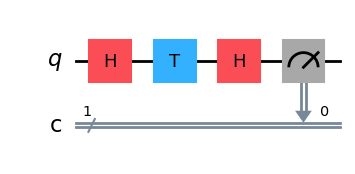

In [3]:
qc_a.draw("mpl")

## 4. Circuit B — biased towards 1 (4 gates: X, H, T, H)

In [4]:
qc_b = QuantumCircuit(1, 1, name="Circuit B")
qc_b.x(0)
qc_b.h(0)
qc_b.t(0)
qc_b.h(0)
qc_b.measure(0, 0)
print(qc_b.draw("text"))

     ┌───┐┌───┐┌───┐┌───┐┌─┐
  q: ┤ X ├┤ H ├┤ T ├┤ H ├┤M├
     └───┘└───┘└───┘└───┘└╥┘
c: 1/═════════════════════╩═
                          0 


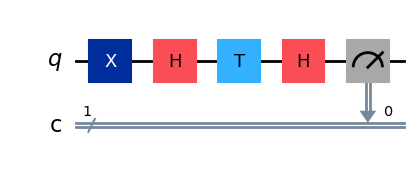

In [5]:
qc_b.draw("mpl")

## 5. Run both circuits for 100 shots

In [6]:
counts_a = run(qc_a)
counts_b = run(qc_b)

print("Circuit A (H,T,H)   :", dict(sorted(counts_a.items())), "| exact:", exact_probs(qc_a))
print("Circuit B (X,H,T,H) :", dict(sorted(counts_b.items())), "| exact:", exact_probs(qc_b))

Circuit A (H,T,H)   : {'0': 82, '1': 18} | exact: {'0': 0.854, '1': 0.146}
Circuit B (X,H,T,H) : {'0': 10, '1': 90} | exact: {'0': 0.146, '1': 0.854}


## 6. Histograms and comparison

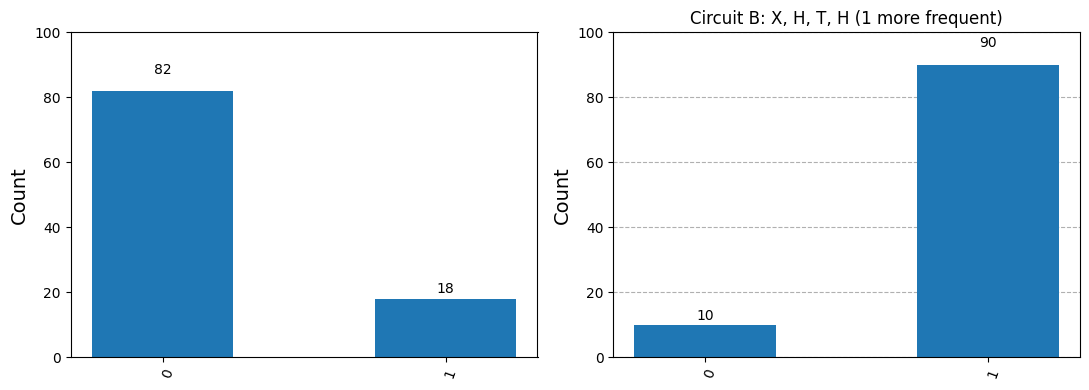

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_histogram(counts_a, ax=axes[0], title="Circuit A: H, T, H (0 more frequent)")
plot_histogram(counts_b, ax=axes[1], title="Circuit B: X, H, T, H (1 more frequent)")
for ax in axes:
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [8]:
print(f"{'Circuit':<10}{'Pred P(0)':<11}{'Pred P(1)':<11}{'Actual 0':<10}{'Actual 1'}")
print("-" * 52)
print(f"{'A':<10}{'~85%':<11}{'~15%':<11}{counts_a.get('0',0):<10}{counts_a.get('1',0)}")
print(f"{'B':<10}{'~15%':<11}{'~85%':<11}{counts_b.get('0',0):<10}{counts_b.get('1',0)}")

Circuit   Pred P(0)  Pred P(1)  Actual 0  Actual 1
----------------------------------------------------
A         ~85%       ~15%       82        18
B         ~15%       ~85%       10        90


## 7. Trying different degrees of bias
To explore other levels of bias, we use a single **RY(θ)** rotation. Starting from |0⟩, it gives P(1) = sin²(θ/2), so larger θ means a stronger pull towards `1`. (This is an extra exploration. It uses only 1 gate, well within the 4-gate limit.)

θ=0              predicted P(1) = 0.00   actual: {'0': 100}
θ=π/3            predicted P(1) = 0.25   actual: {'0': 71, '1': 29}


θ=π/2            predicted P(1) = 0.50   actual: {'0': 59, '1': 41}
θ=2π/3           predicted P(1) = 0.75   actual: {'0': 23, '1': 77}


θ=π              predicted P(1) = 1.00   actual: {'1': 100}


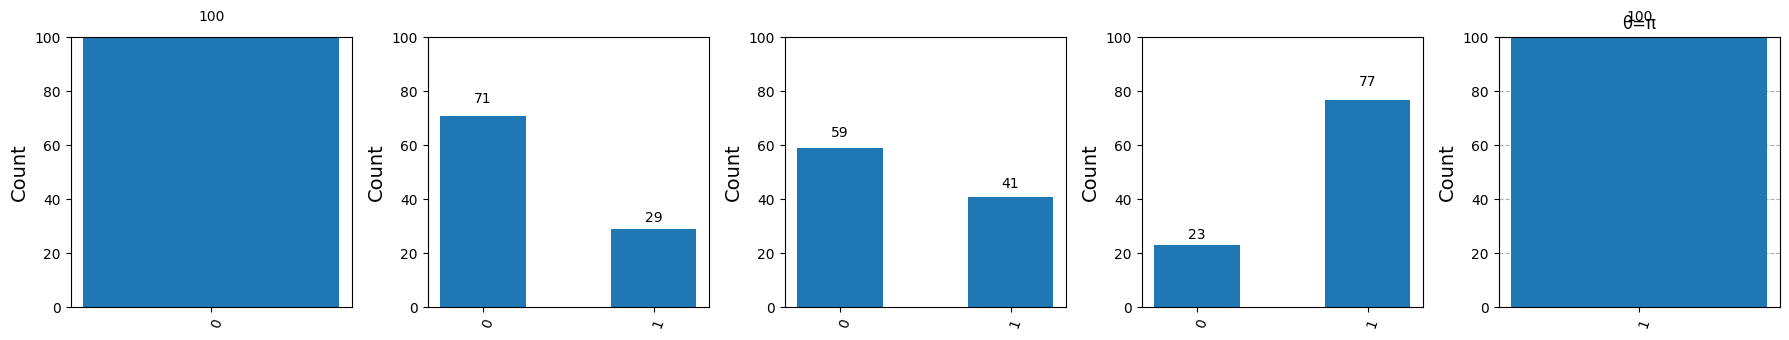

In [9]:
angles = {"θ=0": 0, "θ=π/3": np.pi/3, "θ=π/2": np.pi/2, "θ=2π/3": 2*np.pi/3, "θ=π": np.pi}

results = {}
for label, theta in angles.items():
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0)
    qc.measure(0, 0)
    results[label] = run(qc)
    pred = np.sin(theta/2)**2
    print(f"{label:<16} predicted P(1) = {pred:.2f}   actual: {dict(sorted(results[label].items()))}")

fig, axes = plt.subplots(1, len(results), figsize=(18, 3.5))
for ax, (label, c) in zip(axes, results.items()):
    plot_histogram(c, ax=ax, title=label)
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

## 8. Short explanation: how the gates changed the distribution

- **H** alone gives a 50/50 coin. After H, the qubit sits on the equator of the Bloch sphere, equally far from |0⟩ and |1⟩.
- **T** does not change the 0/1 probabilities by itself. It only rotates the state around the equator (a phase change).
- The **second H** converts that phase into different amplitudes for |0⟩ and |1⟩, so the coin becomes biased (about 85 % / 15 %).
- Adding **X** at the start flips which outcome is favoured, giving the mirror-image bias.
- With **RY(θ)** we can dial the bias to any level, from 0 % to 100 %.

The measured counts fluctuate around the predicted values because each shot is a random sample. With only 100 shots, a few counts of difference from 85/15 is normal.

## Challenge Question
**How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?**

**Answer:** A qubit's state is a combination of |0⟩ and |1⟩ with amplitudes α and β, and the probabilities of measuring `0` and `1` are |α|² and |β|². Quantum gates are rotations of the state on the Bloch sphere, and they change these amplitudes. A gate such as X swaps them, H spreads them into an equal superposition, and rotation gates such as RY shift weight towards |0⟩ or |1⟩. Phase gates (Z, S, T) do not change the probabilities directly, but when followed by another gate like H, the phase turns into a difference in amplitudes. So by choosing and ordering gates, we control how close the final state is to |0⟩ or |1⟩ on the Bloch sphere, and therefore the probability of each measurement outcome. Measurement then collapses the qubit randomly according to those probabilities.